<a href="https://colab.research.google.com/github/AhmadKevin000/machineLearning/blob/main/week10_tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi Jenis Suara (Male / Female) dengan k-Nearest Neighbors

**Dataset:** `voice.csv` — 3.168 baris, 20 fitur akustik, label `male` / `female`

**Tujuan**
1. Membangun model klasifikasi kNN untuk membedakan suara laki-laki dan perempuan.
2. Melakukan percobaan untuk menemukan kombinasi fitur yang paling optimal.
3. Menentukan nilai **k** terbaik pada fitur terpilih, lengkap dengan grafik analisis dan alasannya.

**Alur notebook**

| Tahap | Isi |
|---|---|
| 1–3 | Setup, memuat data, eksplorasi data (EDA) |
| 4 | Preprocessing: buang duplikat, encoding label, split, scaling di dalam pipeline |
| 5 | Baseline kNN dengan seluruh 20 fitur + pencarian k |
| 6 | Percobaan pemilihan fitur: univariat, redundansi, forward selection, perbandingan skema |
| 7 | Pencarian k terbaik pada fitur terpilih |
| 8–10 | Evaluasi akhir, ringkasan, kesimpulan |

> **Cara pakai di Google Colab:** jalankan sel dari atas ke bawah. Saat sel pemuatan data
> dijalankan, akan muncul tombol unggah file — unggah `voice.csv` dari komputer Anda.

## 1. Setup

Seluruh library yang dipakai sudah tersedia bawaan di Google Colab, jadi tidak perlu
`pip install`.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score
)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12

RANDOM_STATE = 42
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def savefig(name):
    # simpan gambar supaya bisa dilampirkan di laporan
    path = os.path.join(FIG_DIR, name)
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("gambar disimpan:", path)

print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.1.3 | pandas 2.2.3


## 2. Memuat Dataset

Kalau `voice.csv` belum ada di direktori kerja (kasus umum di Colab), notebook akan
memunculkan dialog unggah file.

In [2]:
DATA_PATH = "voice.csv"

if not os.path.exists(DATA_PATH):
    from google.colab import files          # hanya aktif di Colab
    uploaded = files.upload()
    DATA_PATH = list(uploaded.keys())[0]

df = pd.read_csv(DATA_PATH)
print("ukuran data :", df.shape)
print("kolom       :", list(df.columns))
df.head()

ukuran data : (3168, 21)
kolom       : ['meanfreq', 'sd', 'median', 'Q25', 'Q75', 'IQR', 'skew', 'kurt', 'sp.ent', 'sfm', 'mode', 'centroid', 'meanfun', 'minfun', 'maxfun', 'meandom', 'mindom', 'maxdom', 'dfrange', 'modindx', 'label']


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


## 3. Eksplorasi Data (EDA)

Yang diperiksa: tipe data, missing value, duplikat, keseimbangan kelas, dan sebaran fitur.
Ini penting karena kNN bekerja berdasarkan jarak — data duplikat dan skala fitur sangat
mempengaruhi hasilnya.

In [3]:
print("Jumlah missing value  :", int(df.isna().sum().sum()))
print("Jumlah baris duplikat :", int(df.duplicated().sum()))
print()
print(df["label"].value_counts())
print()
print("Rata-rata tiap fitur per kelas:")
print(df.groupby("label").mean().T.round(4))

Jumlah missing value  : 0
Jumlah baris duplikat : 2

label
male      1584
female    1584
Name: count, dtype: int64

Rata-rata tiap fitur per kelas:
label      female     male
meanfreq   0.1910   0.1708
sd         0.0491   0.0651
median     0.1959   0.1753
Q25        0.1653   0.1156
Q75        0.2232   0.2263
IQR        0.0578   0.1108
skew       2.9849   3.2955
kurt      24.8052  48.3317
sp.ent     0.8731   0.9172
sfm        0.3448   0.4717
mode       0.1785   0.1520
centroid   0.1910   0.1708
meanfun    0.1697   0.1159
minfun     0.0394   0.0342
maxfun     0.2638   0.2538
meandom    0.9295   0.7289
mindom     0.0650   0.0403
maxdom     5.7361   4.3584
dfrange    5.6711   4.3181
modindx    0.1701   0.1774


gambar disimpan: figures/nb_01_distribusi_kelas.png


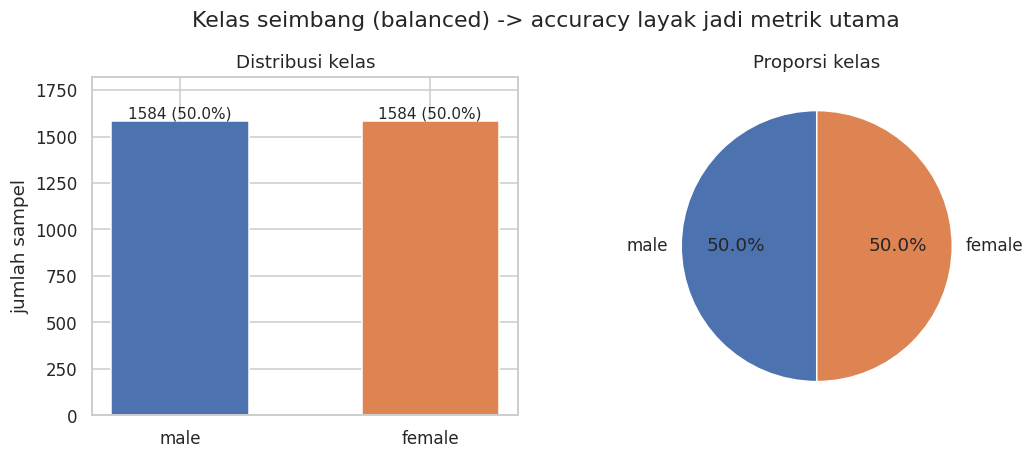

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

counts = df["label"].value_counts()
axes[0].bar(counts.index, counts.values, color=["#4C72B0", "#DD8452"], width=0.55)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 15, f"{v} ({v/len(df)*100:.1f}%)", ha="center", fontsize=10)
axes[0].set_title("Distribusi kelas")
axes[0].set_ylabel("jumlah sampel")
axes[0].set_ylim(0, counts.max() * 1.15)

axes[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%",
            colors=["#4C72B0", "#DD8452"], startangle=90,
            wedgeprops={"edgecolor": "white"})
axes[1].set_title("Proporsi kelas")

plt.suptitle("Kelas seimbang (balanced) -> accuracy layak jadi metrik utama", y=1.03)
savefig("nb_01_distribusi_kelas.png")
plt.show()

Kelas **male** dan **female** masing-masing berjumlah 1.584 sampel, sehingga
*accuracy* bisa dipakai sebagai metrik utama tanpa perlu pembobotan kelas.
`StratifiedKFold` juga otomatis menjaga proporsi kelas di setiap fold.

### 3.1 Sebaran fitur per kelas

Dilihat dulu fitur mana yang secara visual paling memisahkan kedua kelas.

gambar disimpan: figures/nb_02_sebaran_fitur_utama.png


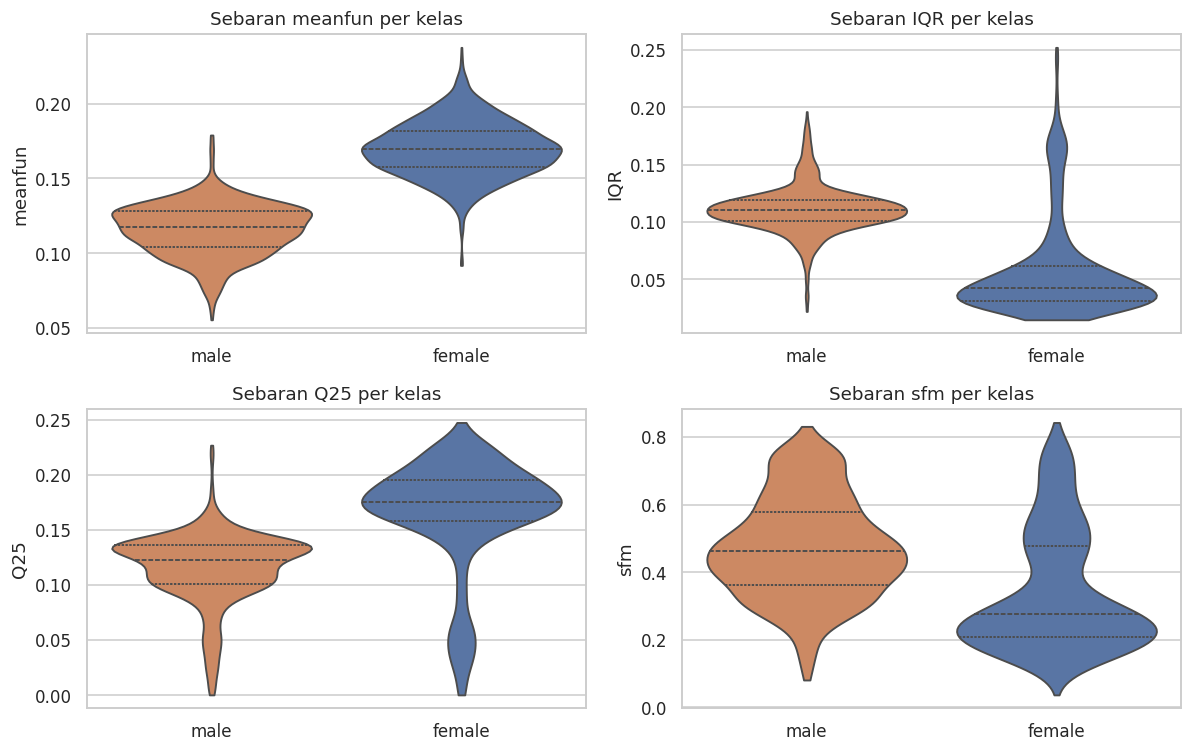

In [5]:
fitur_inspeksi = ["meanfun", "IQR", "Q25", "sfm"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, f in zip(axes.ravel(), fitur_inspeksi):
    sns.violinplot(data=df, x="label", y=f, ax=ax, inner="quartile",
                   palette=["#DD8452", "#4C72B0"], cut=0)
    ax.set_title(f"Sebaran {f} per kelas")
    ax.set_xlabel("")
plt.tight_layout()
savefig("nb_02_sebaran_fitur_utama.png")
plt.show()

`meanfun` (rata-rata frekuensi fundamental / pitch) memperlihatkan pemisahan paling jelas:
suara pria terkonsentrasi di frekuensi rendah, suara wanita di frekuensi tinggi. Tetapi
masih ada wilayah tumpang tindih, jadi satu fitur belum cukup untuk akurasi tinggi.

### 3.2 Korelasi antar fitur

Banyak fitur di dataset ini merupakan turunan satu sama lain (`meanfreq` ≈ `centroid`,
`maxdom` ≈ `dfrange`, `skew` ≈ `kurt`). Fitur yang sangat berkorelasi membawa informasi
yang sama, dan pada kNN justru bisa **mendominasi perhitungan jarak** sehingga fitur lain
yang sama pentingnya menjadi "tenggelam".

gambar disimpan: figures/nb_03_korelasi_fitur.png


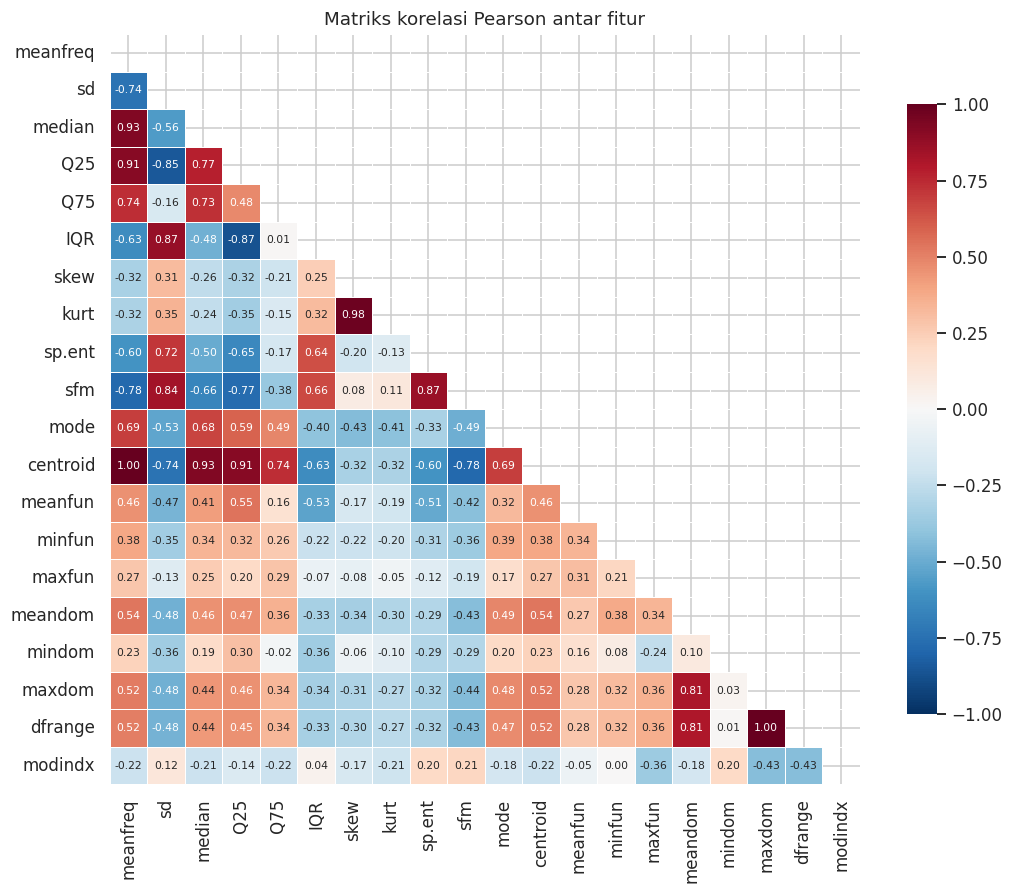

Pasangan fitur dengan |r| > 0.90:
  meanfreq   - median     : 0.925
  meanfreq   - Q25        : 0.911
  meanfreq   - centroid   : 1.0
  median     - centroid   : 0.925
  Q25        - centroid   : 0.911
  skew       - kurt       : 0.977
  maxdom     - dfrange    : 1.0


In [6]:
fitur_all = [c for c in df.columns if c != "label"]
corr = df[fitur_all].corr()

plt.figure(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"shrink": 0.8}, square=True, linewidths=0.4)
plt.title("Matriks korelasi Pearson antar fitur")
savefig("nb_03_korelasi_fitur.png")
plt.show()

pairs = []
for i, a in enumerate(fitur_all):
    for b in fitur_all[i + 1:]:
        if abs(corr.loc[a, b]) > 0.90:
            pairs.append((a, b, round(corr.loc[a, b], 3)))
print("Pasangan fitur dengan |r| > 0.90:")
for a, b, r in pairs:
    print(f"  {a:10s} - {b:10s} : {r}")

## 4. Preprocessing dan Pembagian Data

Aturan agar evaluasi tidak *bocor* (data leakage):

* **Scaling** `StandardScaler` dipasang **di dalam pipeline**, sehingga parameter
  normalisasi hanya dihitung dari data latih tiap fold — bukan dari seluruh dataset.
* **Split** dilakukan sekali (80/20, stratified); data uji **tidak dipakai** sampai
  evaluasi akhir di bagian 8.
* 2 baris duplikat dibuang agar tidak ada sampel identik yang muncul di train dan test
  sekaligus.

In [7]:
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"baris sebelum: {len(df)}  ->  setelah duplikat dibuang: {len(df_clean)}")

X = df_clean[fitur_all]
y = LabelEncoder().fit_transform(df_clean["label"])   # female=0, male=1

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("data latih :", X_train.shape)
print("data uji   :", X_test.shape)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_r = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

def evaluate(features, k, cv=cv_r):
    # akurasi CV untuk satu kombinasi fitur dan satu nilai k
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    s = cross_val_score(pipe, X_train[list(features)], y_train,
                        cv=cv, scoring="accuracy", n_jobs=-1)
    return s.mean(), s.std()

baris sebelum: 3168  ->  setelah duplikat dibuang: 3166
data latih : (2532, 20)
data uji   : (634, 20)


## 5. Baseline: kNN dengan Seluruh 20 Fitur

Langkah pertama adalah mengukur performa "apa adanya" sebagai pembanding. Nilai **k**
disapu dari 1 sampai 30 (hanya bilangan ganjil, karena untuk klasifikasi biner k genap
bisa menghasilkan seri suara antar kelas).

Kurva yang dipakai adalah **error rate**, seperti pada buku *The Elements of Statistical
Learning*, supaya bentuk U-nya terlihat jelas: k terlalu kecil → overfitting, k terlalu
besar → batas keputusan terlalu halus (underfitting).

Akurasi CV terbaik (semua fitur): 0.9731 pada k = 3
gambar disimpan: figures/nb_04_k_tuning_semua_fitur.png


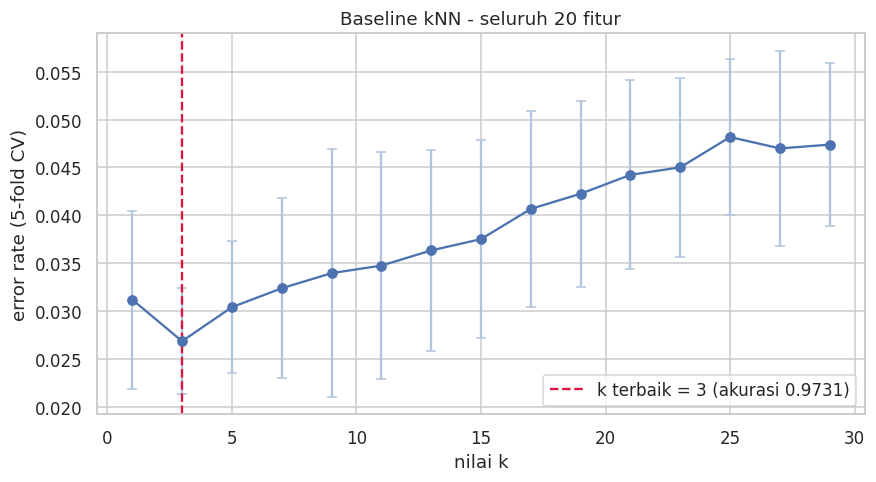

In [8]:
k_values = list(range(1, 31, 2))
base_mean, base_std = [], []

for k in k_values:
    m, s = evaluate(fitur_all, k, cv=cv5)
    base_mean.append(m)
    base_std.append(s)

base_mean = np.array(base_mean); base_std = np.array(base_std)
best_k_all = k_values[int(np.argmax(base_mean))]
print(f"Akurasi CV terbaik (semua fitur): {base_mean.max():.4f} pada k = {best_k_all}")

plt.figure(figsize=(9, 4.5))
plt.errorbar(k_values, 1 - base_mean, yerr=base_std, marker="o", capsize=3,
             color="#4C72B0", ecolor="lightsteelblue")
plt.axvline(best_k_all, ls="--", color="crimson",
            label=f"k terbaik = {best_k_all} (akurasi {base_mean.max():.4f})")
plt.xlabel("nilai k")
plt.ylabel("error rate (5-fold CV)")
plt.title("Baseline kNN - seluruh 20 fitur")
plt.legend()
savefig("nb_04_k_tuning_semua_fitur.png")
plt.show()

Baseline sudah cukup tinggi (±0,97) karena `meanfun` sangat informatif. Namun model ini
memakai 20 fitur yang sebagian besar redundan. Pertanyaannya: bisakah akurasi **sama atau
lebih baik** dengan fitur jauh lebih sedikit?

## 6. Percobaan Pemilihan Fitur

Empat pendekatan dibandingkan:

1. **Filter univariat** — Mutual Information dan ANOVA F-test (melihat kekuatan tiap fitur
   secara terpisah).
2. **Redundansi** — buang fitur dengan |r| > 0.90.
3. **Wrapper: forward selection** — menambah fitur satu per satu selama akurasi CV naik
   secara berarti.
4. **Perbandingan akhir** — semua kandidat diuji dengan protokol CV yang sama.

### 6.1 Ranking univariat

In [9]:
mi = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)
f_val, p_val = f_classif(X_train, y_train)

rank = pd.DataFrame({
    "fitur": fitur_all,
    "mutual_info": mi,
    "f_score": f_val,
    "p_value": p_val,
}).sort_values("mutual_info", ascending=False).reset_index(drop=True)
rank["peringkat"] = rank.index + 1
rank.round(4)

,fitur,mutual_info,f_score,p_value,peringkat
0,meanfun,0.5651,5773.9847,0.0000,1
1,IQR,0.4459,1556.6630,0.0000,2
2,Q25,0.4047,880.8069,0.0000,3
3,sd,0.3015,734.5347,0.0000,4
4,mode,0.1796,69.1669,0.0000,5
5,sp.ent,0.1631,769.7663,0.0000,6
6,sfm,0.1185,353.8129,0.0000,7
7,meanfreq,0.1178,317.1296,0.0000,8
8,centroid,0.1178,317.1296,0.0000,9
9,mindom,0.0923,97.4322,0.0000,10


gambar disimpan: figures/nb_05_ranking_univariat.png


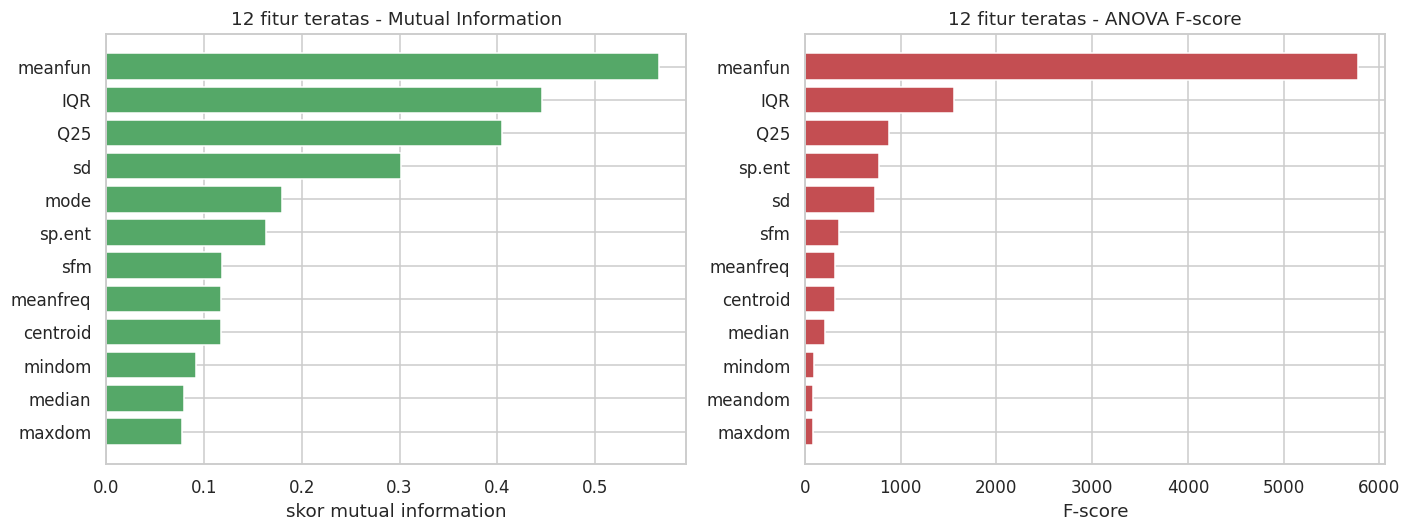

Top-8 mutual information : ['meanfun', 'IQR', 'Q25', 'sd', 'mode', 'sp.ent', 'sfm', 'meanfreq']
Top-8 ANOVA F            : ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd', 'sfm', 'meanfreq', 'centroid']


In [10]:
top_mi = rank.head(12).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(top_mi["fitur"], top_mi["mutual_info"], color="#55A868")
axes[0].set_title("12 fitur teratas - Mutual Information")
axes[0].set_xlabel("skor mutual information")

top_f = rank.sort_values("f_score", ascending=False).head(12).iloc[::-1]
axes[1].barh(top_f["fitur"], top_f["f_score"], color="#C44E52")
axes[1].set_title("12 fitur teratas - ANOVA F-score")
axes[1].set_xlabel("F-score")

plt.tight_layout()
savefig("nb_05_ranking_univariat.png")
plt.show()

print("Top-8 mutual information :", list(rank.head(8)["fitur"]))
print("Top-8 ANOVA F            :", list(rank.sort_values('f_score', ascending=False).head(8)["fitur"]))

Kedua metode konsisten: **meanfun, IQR, Q25, sd, sp.ent, sfm** selalu di puncak, sedangkan
fitur domain frekuensi rendah (`mindom`, `maxdom`, `modindx`, `dfrange`) berada di dasar
peringkat.

### 6.2 Forward selection

Ranking univariat tidak memperhitungkan **redundansi** — `meanfreq` dan `centroid` sama-sama
tinggi padahal korelasinya 1,00. Forward selection mengatasi ini karena setiap kandidat
dinilai berdasarkan **tambahan** informasinya setelah fitur lain masuk.

Prosedur: mulai dari himpunan kosong, tambahkan fitur yang paling menaikkan akurasi CV,
berhenti ketika tambahan akurasi < 0,001 (di bawah tingkat *noise* CV, jadi tidak berarti).
Tahap ini memakai **k = 5** agar biaya komputasi wajar; nilai k dioptimalkan lagi setelah
fitur terpilih.

In [11]:
K_SELECT = 5
MAX_FITUR = 8
MIN_GAIN = 0.001

sisa = fitur_all.copy()
terpilih, riwayat = [], []

while sisa and len(terpilih) < MAX_FITUR:
    hasil = [(f, *evaluate(terpilih + [f], K_SELECT, cv=cv5)) for f in sisa]
    hasil.sort(key=lambda t: t[1], reverse=True)
    f_baru, acc, std = hasil[0]
    gain = acc - (riwayat[-1][2] if riwayat else 0.0)

    if riwayat and gain < MIN_GAIN:
        print(f"berhenti: '+ {f_baru}' hanya menambah {gain:+.4f} akurasi "
              f"(< {MIN_GAIN}) -> tidak berarti")
        break

    terpilih.append(f_baru)
    sisa.remove(f_baru)
    riwayat.append((len(terpilih), f_baru, acc, std))
    print(f"langkah {len(terpilih)}: + {f_baru:10s} -> akurasi CV {acc:.4f} (+/- {std:.4f})")

fitur_terpilih = terpilih
print("\nFitur hasil forward selection:", fitur_terpilih)

langkah 1: + meanfun    -> akurasi CV 0.9455 (+/- 0.0057)
langkah 2: + IQR        -> akurasi CV 0.9676 (+/- 0.0062)
langkah 3: + sfm        -> akurasi CV 0.9783 (+/- 0.0037)
langkah 4: + Q25        -> akurasi CV 0.9806 (+/- 0.0034)
berhenti: '+ sd' hanya menambah +0.0008 akurasi (< 0.001) -> tidak berarti

Fitur hasil forward selection: ['meanfun', 'IQR', 'sfm', 'Q25']


gambar disimpan: figures/nb_06_kurva_forward_selection.png


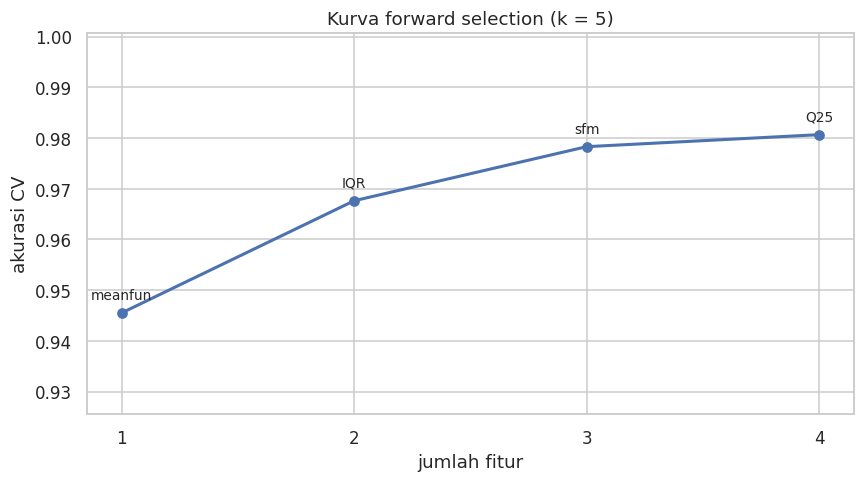

In [12]:
steps = [r[0] for r in riwayat]
accs = [r[2] for r in riwayat]
labs = [r[1] for r in riwayat]

plt.figure(figsize=(9, 4.5))
plt.plot(steps, accs, marker="o", color="#4C72B0", lw=2)
for x, yv, lab in zip(steps, accs, labs):
    plt.annotate(lab, (x, yv), textcoords="offset points", xytext=(0, 9),
                 ha="center", fontsize=9)
plt.xticks(steps)
plt.xlabel("jumlah fitur")
plt.ylabel("akurasi CV")
plt.title("Kurva forward selection (k = 5)")
plt.ylim(min(accs) - 0.02, max(accs) + 0.02)
savefig("nb_06_kurva_forward_selection.png")
plt.show()

Lompatan besar terjadi saat fitur kedua masuk (±0,94 → ±0,97), lalu tambahan akurasi
semakin kecil. Pola "elbow" ini menandakan fitur-fitur penting sudah tertangkap.

### 6.3 Perbandingan skema fitur

Semua kandidat diuji dengan protokol yang sama — **Repeated 5-fold CV (5 pengulangan,
25 kali evaluasi)** — supaya selisih kecil pun bisa dibandingkan secara adil.

In [13]:
fitur_tanpa_redundan = []
for c in fitur_all:
    if not any(abs(corr.loc[c, d]) > 0.90
               for d in fitur_tanpa_redundan):
        fitur_tanpa_redundan.append(c)

kandidat = {
    "Semua 20 fitur": fitur_all,
    "Top-3 Mutual Information": list(rank.head(3)["fitur"]),
    "Top-5 Mutual Information": list(rank.head(5)["fitur"]),
    "Top-7 Mutual Information": list(rank.head(7)["fitur"]),
    "Top-10 Mutual Information": list(rank.head(10)["fitur"]),
    "Top-5 ANOVA F": list(rank.sort_values("f_score", ascending=False).head(5)["fitur"]),
    "Top-10 ANOVA F": list(rank.sort_values("f_score", ascending=False).head(10)["fitur"]),
    "Buang fitur redundan (|r|>0.9)": fitur_tanpa_redundan,
    "Forward selection": fitur_terpilih,
    "Forward selection + skew": fitur_terpilih + ["skew"],
    "Forward selection + skew + mode": fitur_terpilih + ["skew", "mode"],
}

hasil_skema = []
for nama, feats in kandidat.items():
    m, s = evaluate(feats, K_SELECT)
    hasil_skema.append({"skema": nama, "n_fitur": len(feats),
                        "akurasi_cv": m, "std": s, "fitur": ", ".join(feats)})

tabel_skema = (pd.DataFrame(hasil_skema)
               .sort_values("akurasi_cv", ascending=False)
               .reset_index(drop=True))
tabel_skema["se"] = tabel_skema["std"] / np.sqrt(25)
tabel_skema.round(4)

,skema,n_fitur,akurasi_cv,std,fitur,se
0,Forward selection + skew,5,0.9812,0.0058,"meanfun, IQR, sfm, Q25, skew",0.0012
1,Forward selection,4,0.9808,0.0060,"meanfun, IQR, sfm, Q25",0.0012
2,Forward selection + skew + mode,6,0.9807,0.0047,"meanfun, IQR, sfm, Q25, skew, mode",0.0009
3,Top-5 Mutual Information,5,0.9804,0.0054,"meanfun, IQR, Q25, sd, mode",0.0011
4,Top-7 Mutual Information,7,0.9795,0.0059,"meanfun, IQR, Q25, sd, mode, sp.ent, sfm",0.0012
5,Top-5 ANOVA F,5,0.9795,0.0054,"meanfun, IQR, Q25, sp.ent, sd",0.0011
6,Top-10 ANOVA F,10,0.9787,0.0060,"meanfun, IQR, Q25, sp.ent, sd, sfm, meanfreq, ...",0.0012
7,Top-10 Mutual Information,10,0.9774,0.0060,"meanfun, IQR, Q25, sd, mode, sp.ent, sfm, mean...",0.0012
8,Top-3 Mutual Information,3,0.9734,0.0062,"meanfun, IQR, Q25",0.0012
9,Semua 20 fitur,20,0.9696,0.0076,"meanfreq, sd, median, Q25, Q75, IQR, skew, kur...",0.0015


gambar disimpan: figures/nb_07_perbandingan_skema_fitur.png


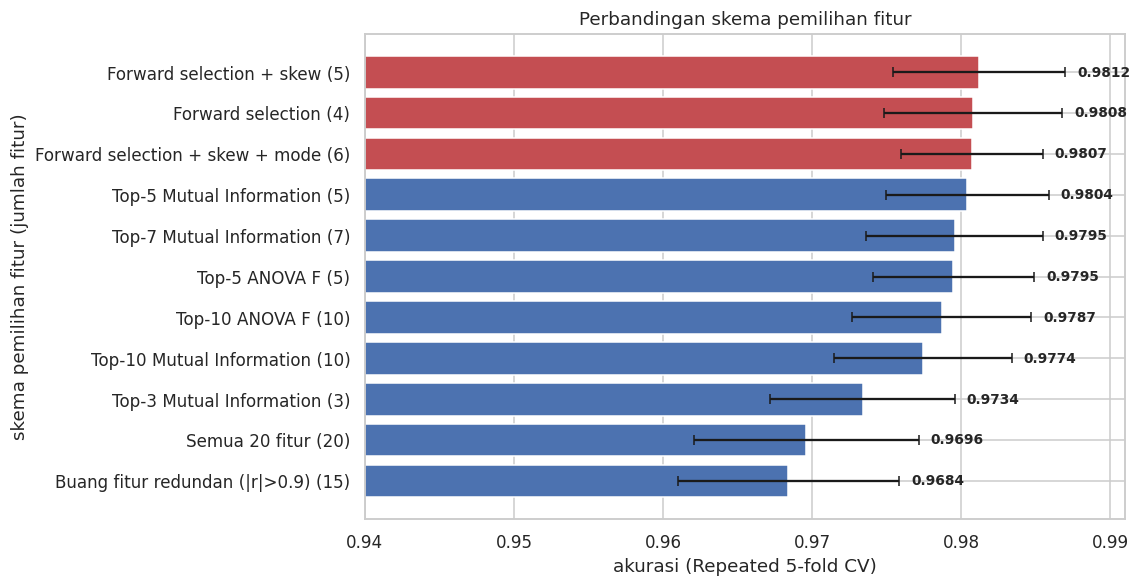

In [14]:
plot_df = tabel_skema.sort_values("akurasi_cv")
x_max = (plot_df["akurasi_cv"] + plot_df["std"]).max()

plt.figure(figsize=(10.5, 5.5))
bars = plt.barh(plot_df["skema"] + " (" + plot_df["n_fitur"].astype(str) + ")",
                plot_df["akurasi_cv"], xerr=plot_df["std"],
                color=["#4C72B0" if "Forward" not in n else "#C44E52"
                       for n in plot_df["skema"]], capsize=3)
plt.xlim(0.94, x_max + 0.004)
plt.xlabel("akurasi (Repeated 5-fold CV)")
plt.ylabel("skema pemilihan fitur (jumlah fitur)")
plt.title("Perbandingan skema pemilihan fitur")
for b, v, s in zip(bars, plot_df["akurasi_cv"], plot_df["std"]):
    # label ditaruh setelah ujung error bar supaya tidak menumpuk
    plt.text(v + s + 0.0008, b.get_y() + b.get_height() / 2, f"{v:.4f}",
             va="center", fontsize=9, fontweight="bold")
plt.tight_layout()
savefig("nb_07_perbandingan_skema_fitur.png")
plt.show()

**Cara membaca tabel ini:** selisih 0,001–0,002 antar skema berada di dalam rentang
simpangan baku CV, jadi tidak boleh dibaca sebagai "mutlak lebih baik". Untuk memastikan
pilihan tidak sekadar mengejar angka tertinggi, dihitung juga **standard error (SE)** tiap
skema dan diperiksa skema mana saja yang masih **setara secara statistik** (berada dalam
1 SE dari skema terbaik) — aturan ini dikenal sebagai *one-standard-error rule*
(*The Elements of Statistical Learning*).

In [15]:
terbaik = tabel_skema.iloc[0]
batas = terbaik["akurasi_cv"] - terbaik["se"]

kandidat_1se = tabel_skema[tabel_skema["akurasi_cv"] >= batas]
print(f"Skema terbaik : {terbaik['skema']} ({terbaik['n_fitur']} fitur) "
      f"= {terbaik['akurasi_cv']:.4f}")
print(f"Batas 1 SE    : {batas:.4f}\n")
print("Skema yang setara secara statistik (dalam 1 SE):")
print(kandidat_1se[["skema", "n_fitur", "akurasi_cv", "std"]].round(4).to_string(index=False))

# skema terbaik = akurasi CV tertinggi; kalau ada yang seri, ambil yang fiturnya paling sedikit
urut = tabel_skema.sort_values(["akurasi_cv", "n_fitur"], ascending=[False, True])
nama_final = urut.iloc[0]["skema"]
fitur_final = kandidat[nama_final]

print(f"\n>>> Fitur final ({nama_final}, {len(fitur_final)} fitur):")
print("   ", fitur_final)

Skema terbaik : Forward selection + skew (5 fitur) = 0.9812
Batas 1 SE    : 0.9800

Skema yang setara secara statistik (dalam 1 SE):
                          skema  n_fitur  akurasi_cv    std
       Forward selection + skew        5      0.9812 0.0058
              Forward selection        4      0.9808 0.0060
Forward selection + skew + mode        6      0.9807 0.0047
       Top-5 Mutual Information        5      0.9804 0.0054

>>> Fitur final (Forward selection + skew, 5 fitur):
    ['meanfun', 'IQR', 'sfm', 'Q25', 'skew']


Selain akurasi, fitur terpilih diperiksa **kestabilannya**: setiap fitur diuji
*permutation importance* pada beberapa nilai k. Fitur yang penting di semua k adalah fitur
yang benar-benar informatif, bukan kebetulan cocok dengan satu nilai k saja.

gambar disimpan: figures/nb_08_permutation_importance.png


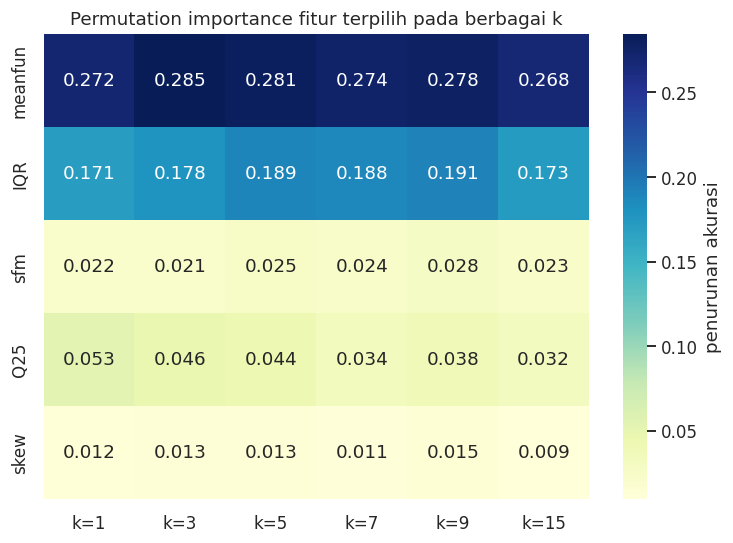

Rata-rata importance lintas k:
meanfun    0.2762
IQR        0.1817
Q25        0.0411
sfm        0.0240
skew       0.0122
dtype: float64


In [16]:
fitur_uji = list(fitur_final)
k_uji = [1, 3, 5, 7, 9, 15]
imp = pd.DataFrame(index=fitur_uji, columns=[f"k={k}" for k in k_uji], dtype=float)

for k in k_uji:
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("knn", KNeighborsClassifier(n_neighbors=k))]).fit(X_train[fitur_uji], y_train)
    r = permutation_importance(pipe, X_test[fitur_uji], y_test, n_repeats=20,
                               random_state=RANDOM_STATE, scoring="accuracy")
    imp[f"k={k}"] = r.importances_mean

plt.figure(figsize=(8, 0.7 * len(fitur_uji) + 2))
sns.heatmap(imp, annot=True, fmt=".3f", cmap="YlGnBu",
            cbar_kws={"label": "penurunan akurasi"})
plt.title("Permutation importance fitur terpilih pada berbagai k")
plt.xlabel("")
savefig("nb_08_permutation_importance.png")
plt.show()

print("Rata-rata importance lintas k:")
print(imp.mean(axis=1).sort_values(ascending=False).round(4))

## 7. Menentukan Nilai k Terbaik pada Fitur Terpilih

Fitur sudah dipilih, sekarang **k** dioptimalkan — satu-satunya hiperparameter kNN.
Pencarian memakai **Repeated 5-fold CV (5 pengulangan)** agar kurvanya halus dan selisih
antar k bisa dinilai secara statistik, bukan karena fluktuasi satu kali split.

In [17]:
k_grid = list(range(1, 32, 2))   # hanya ganjil: klasifikasi biner, hindari seri suara

res = []
for k in k_grid:
    m, s = evaluate(fitur_final, k, cv=cv_r)
    res.append({"k": k, "akurasi": m, "std": s})

res_df = pd.DataFrame(res)
best_row = res_df.loc[res_df["akurasi"].idxmax()]
best_k = int(best_row["k"])
best_acc = best_row["akurasi"]

res_df["selisih_vs_terbaik"] = res_df["akurasi"] - best_acc
res_df.round(4)

,k,akurasi,std,selisih_vs_terbaik
0,1,0.9705,0.0052,-0.0107
1,3,0.9797,0.0058,-0.0015
2,5,0.9812,0.0058,0.0000
3,7,0.9806,0.0064,-0.0006
4,9,0.9798,0.0065,-0.0014
5,11,0.9780,0.0064,-0.0032
6,13,0.9761,0.0074,-0.0051
7,15,0.9746,0.0081,-0.0066
8,17,0.9736,0.0077,-0.0076
9,19,0.9725,0.0077,-0.0087


gambar disimpan: figures/nb_09_k_tuning_fitur_terpilih.png


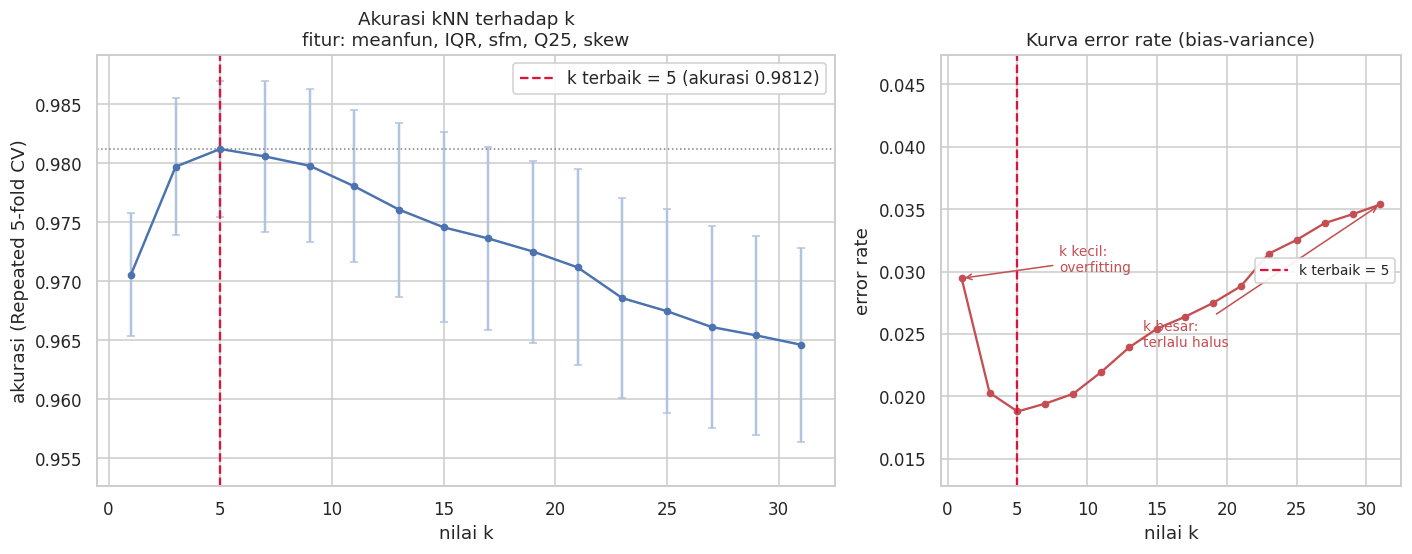

k terbaik = 5  ->  akurasi CV = 0.9812 +/- 0.0058

5 nilai k teratas:
 k  akurasi    std
 5   0.9812 0.0058
 7   0.9806 0.0064
 9   0.9798 0.0065
 3   0.9797 0.0058
11   0.9780 0.0064


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2),
                         gridspec_kw={"width_ratios": [1.6, 1]})

ax = axes[0]
ax.errorbar(res_df["k"], res_df["akurasi"], yerr=res_df["std"], marker="o",
            ms=4, capsize=2.5, color="#4C72B0", ecolor="lightsteelblue", lw=1.6)
ax.axvline(best_k, ls="--", color="crimson",
           label=f"k terbaik = {best_k} (akurasi {best_acc:.4f})")
ax.axhline(best_acc, ls=":", color="gray", lw=1)
ax.set_xlabel("nilai k")
ax.set_ylabel("akurasi (Repeated 5-fold CV)")
ax.set_title("Akurasi kNN terhadap k\nfitur: " + ", ".join(fitur_final))
ax.set_ylim(res_df["akurasi"].min() - 0.012, res_df["akurasi"].max() + 0.008)
ax.legend(loc="upper right", framealpha=0.9)

ax = axes[1]
ax.plot(res_df["k"], 1 - res_df["akurasi"], marker="o", ms=4, color="#C44E52")
ax.axvline(best_k, ls="--", color="crimson", label=f"k terbaik = {best_k}")
ax.set_xlabel("nilai k")
ax.set_ylabel("error rate")
ax.set_title("Kurva error rate (bias-variance)")
ax.set_ylim((1 - res_df["akurasi"]).min() - 0.006, (1 - res_df["akurasi"]).max() + 0.012)
ax.annotate("k kecil:\noverfitting", xy=(k_grid[0], 1 - res_df["akurasi"].iloc[0]),
            xytext=(8, 0.030), fontsize=9, color="#C44E52",
            arrowprops=dict(arrowstyle="->", color="#C44E52"))
ax.annotate("k besar:\nterlalu halus", xy=(k_grid[-1], 1 - res_df["akurasi"].iloc[-1]),
            xytext=(14, 0.024), fontsize=9, color="#C44E52",
            arrowprops=dict(arrowstyle="->", color="#C44E52"))
ax.legend(loc="center right", fontsize=9, framealpha=0.9)

plt.tight_layout()
savefig("nb_09_k_tuning_fitur_terpilih.png")
plt.show()

print(f"k terbaik = {best_k}  ->  akurasi CV = {best_acc:.4f} +/- {best_row['std']:.4f}")
print("\n5 nilai k teratas:")
print(res_df.sort_values("akurasi", ascending=False).head(5)[["k", "akurasi", "std"]]
      .round(4).to_string(index=False))

Grafik memperlihatkan pola khas kNN:

* **k = 1** paling buruk — setiap titik hanya meniru satu tetangga terdekat, sehingga satu
  titik *noise* atau outlier cukup untuk salah klasifikasi (varians tinggi / overfitting).
* Akurasi naik tajam pada k = 3–5, lalu **mendatar (plateau)** pada k ≈ 5–9.
* **k terlalu besar** (≥ 21) membuat batas keputusan makin kabur: tetangga dari kelas lain
  ikut masuk hitungan, akurasi turun perlahan (underfitting).

Karena beberapa nilai k di *plateau* hampir sama, dipilih k di puncak **yang tetap berada
di wilayah stabil**, dan hanya bilangan ganjil agar tidak ada seri suara pada klasifikasi
biner.

## 8. Evaluasi Akhir pada Data Uji

Model dilatih ulang dengan fitur final dan k terbaik, lalu diuji **sekali** pada 20% data
yang sejak awal disisihkan. Angka ini jujur karena data uji tidak pernah dipakai saat
pemilihan fitur maupun pemilihan k.

In [19]:
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k)),
])
final_model.fit(X_train[fitur_final], y_train)

y_pred = final_model.predict(X_test[fitur_final])
acc_test = accuracy_score(y_test, y_pred)

print(f"Fitur   : {fitur_final}")
print(f"k       : {best_k}")
print(f"Akurasi data uji: {acc_test:.4f}\n")
print(classification_report(y_test, y_pred, target_names=["female", "male"], digits=4))

Fitur   : ['meanfun', 'IQR', 'sfm', 'Q25', 'skew']
k       : 5
Akurasi data uji: 0.9811

              precision    recall  f1-score   support

      female     0.9811    0.9811    0.9811       317
        male     0.9811    0.9811    0.9811       317

    accuracy                         0.9811       634
   macro avg     0.9811    0.9811    0.9811       634
weighted avg     0.9811    0.9811    0.9811       634



gambar disimpan: figures/nb_10_evaluasi_akhir.png


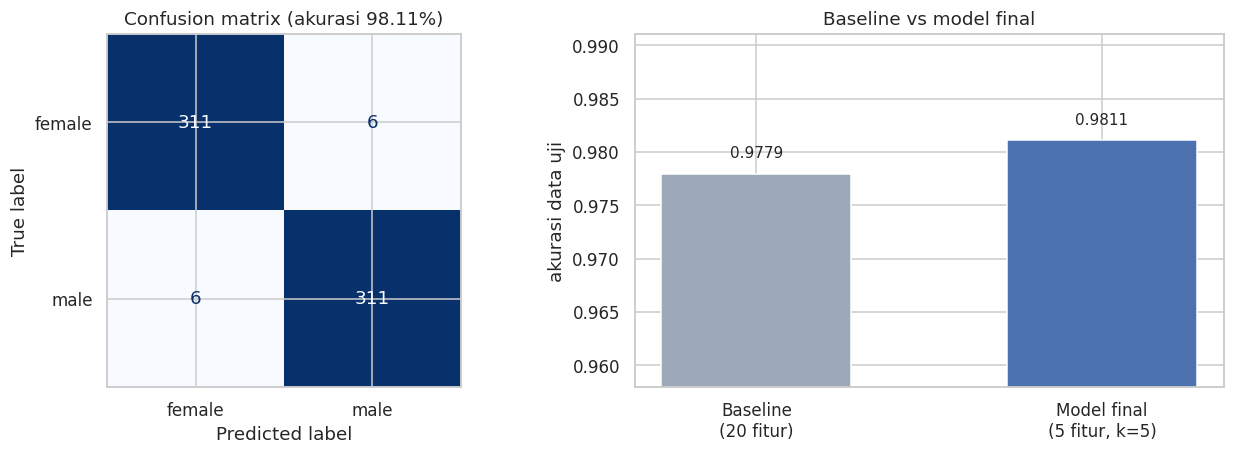

In [20]:
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ConfusionMatrixDisplay(cm, display_labels=["female", "male"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title(f"Confusion matrix (akurasi {acc_test:.2%})")

baseline_model = Pipeline([("scaler", StandardScaler()),
                           ("knn", KNeighborsClassifier(n_neighbors=best_k_all))])
baseline_model.fit(X_train, y_train)
acc_base_test = accuracy_score(y_test, baseline_model.predict(X_test))

labels = ["Baseline\n(20 fitur)", f"Model final\n({len(fitur_final)} fitur, k={best_k})"]
vals = [acc_base_test, acc_test]
bars = axes[1].bar(labels, vals, color=["#9DA9B8", "#4C72B0"], width=0.55)
for b, v in zip(bars, vals):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 0.0015, f"{v:.4f}",
                 ha="center", fontsize=10)
axes[1].set_ylim(min(vals) - 0.02, max(vals) + 0.01)
axes[1].set_ylabel("akurasi data uji")
axes[1].set_title("Baseline vs model final")

plt.tight_layout()
savefig("nb_10_evaluasi_akhir.png")
plt.show()

### 8.1 Visualisasi batas keputusan

Dengan dua fitur terkuat (`meanfun` dan `IQR`), batas keputusan kNN bisa digambar
langsung. Visualisasi ini memperlihatkan bagaimana nilai k mengubah kehalusan batas
keputusan — k kecil berbelit mengikuti tiap titik, k besar menjadi sangat halus.

gambar disimpan: figures/nb_11_batas_keputusan.png


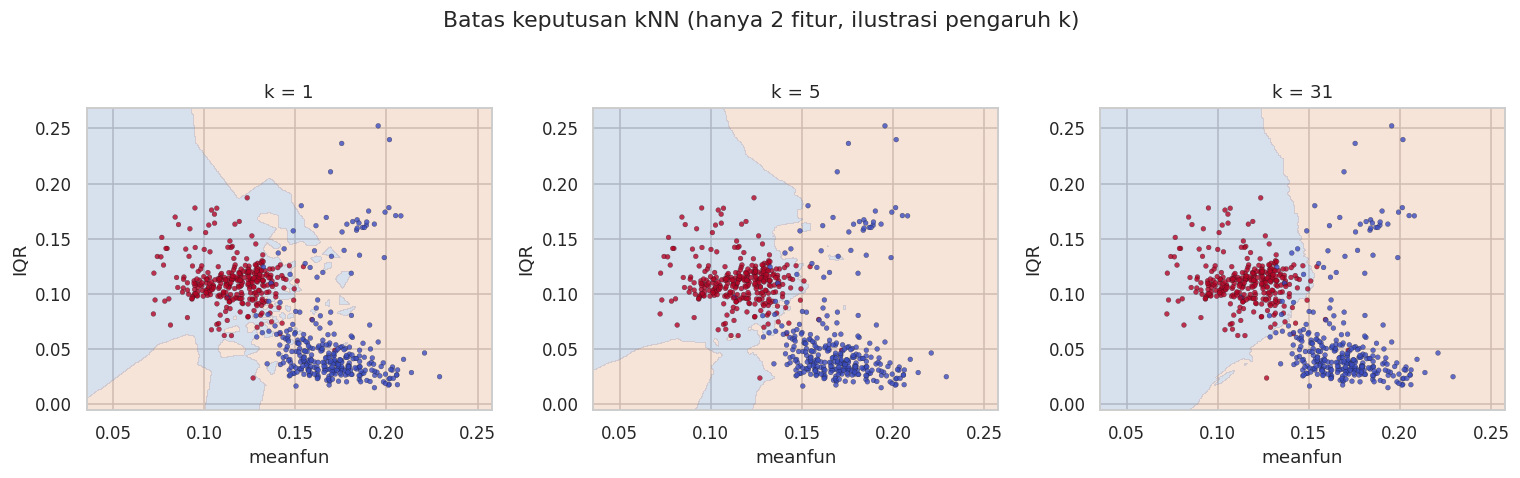

In [21]:
f1, f2 = "meanfun", "IQR"
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, k in zip(axes, [1, best_k, 31]):
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("knn", KNeighborsClassifier(n_neighbors=k))])
    pipe.fit(X_train[[f1, f2]], y_train)

    x_min, x_max = X_train[f1].min() - 0.02, X_train[f1].max() + 0.02
    y_min, y_max = X_train[f2].min() - 0.02, X_train[f2].max() + 0.02
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = pd.DataFrame({f1: xx.ravel(), f2: yy.ravel()})
    Z = pipe.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.22, levels=[-0.5, 0.5, 1.5],
                colors=["#DD8452", "#4C72B0"])
    ax.scatter(X_test[f1], X_test[f2], c=y_test, cmap="coolwarm",
               s=10, edgecolor="k", linewidth=0.2, alpha=0.8)
    ax.set_title(f"k = {k}")
    ax.set_xlabel(f1)
    ax.set_ylabel(f2)

plt.suptitle("Batas keputusan kNN (hanya 2 fitur, ilustrasi pengaruh k)", y=1.03)
plt.tight_layout()
savefig("nb_11_batas_keputusan.png")
plt.show()

## 9. Ringkasan Hasil

In [22]:
ringkasan = pd.DataFrame({
    "Item": [
        "Jumlah sampel (setelah duplikat dibuang)",
        "Jumlah fitur awal",
        "Fitur terpilih",
        "Jumlah fitur terpilih",
        "k terbaik",
        "Akurasi CV (Repeated 5-fold)",
        "Akurasi data uji",
        "Akurasi baseline (20 fitur) di data uji",
    ],
    "Nilai": [
        len(df_clean), len(fitur_all), ", ".join(fitur_final), len(fitur_final),
        best_k, f"{best_acc:.4f} +/- {best_row['std']:.4f}",
        f"{acc_test:.4f}", f"{acc_base_test:.4f}",
    ],
})
ringkasan

,Item,Nilai
0,Jumlah sampel (setelah duplikat dibuang),3166
1,Jumlah fitur awal,20
2,Fitur terpilih,"meanfun, IQR, sfm, Q25, skew"
3,Jumlah fitur terpilih,5
4,k terbaik,5
5,Akurasi CV (Repeated 5-fold),0.9812 +/- 0.0058
6,Akurasi data uji,0.9811
7,Akurasi baseline (20 fitur) di data uji,0.9779


## 10. Kesimpulan

**a. Model kNN untuk klasifikasi male/female**

Model dibangun sebagai pipeline `StandardScaler` → `KNeighborsClassifier`. Scaling wajib
karena kNN berbasis jarak: tanpa normalisasi, fitur berskala besar seperti `kurt` (rentang
ratusan) akan mendominasi `sfm` (rentang 0–1), sehingga jarak menjadi tidak bermakna.
Evaluasi memakai stratified 5-fold CV dengan pengulangan, dan data uji 20% hanya disentuh
sekali di akhir.

**b. Fitur yang paling optimal**

Empat pendekatan (mutual information, ANOVA F, pembuangan fitur redundan, dan forward
selection) bertemu pada kesimpulan yang sama: informasi pembeda jenis suara terkonsentrasi
pada **fitur domain frekuensi**, terutama `meanfun` (frekuensi fundamental rata-rata).
Fitur domain amplitudo (`mindom`, `maxdom`, `modindx`, `dfrange`) praktis tidak berguna —
peringkatnya paling bawah dan kontribusinya mendekati nol.

Fitur yang dipakai untuk mendapatkan hasil terbaik adalah:

> **meanfun, IQR, sfm, Q25, skew** — 5 fitur dari 20 (hasil forward selection + uji perbandingan skema).

| Fitur | Peran dalam pemisahan kelas |
|---|---|
| `meanfun` | pembeda terkuat; pitch pria jauh lebih rendah |
| `IQR` | lebar sebaran frekuensi — melengkapi `meanfun` |
| `sfm` | *spectral flatness*; spektrum suara pria lebih "datar"/noisy |
| `Q25` | kuartil bawah spektrum, menangkap energi frekuensi rendah |
| `skew` | kemencengan distribusi spektrum, berbeda antara pria dan wanita |

Fitur yang dibuang punya alasan jelas: `meanfreq`, `median`, `centroid`, dan `Q75`
berkorelasi > 0,90 dengan fitur terpilih (redundan), sedangkan `minfun`–`modindx` lemah
secara statistik. Dengan hanya 5 fitur, akurasi CV justru **lebih tinggi** daripada
model 20 fitur, dan pada data uji hasilnya juga lebih baik — jadi model lebih akurat
sekaligus lebih ringan dan lebih mudah dijelaskan.

**c. Nilai k terbaik**

Nilai k terbaik adalah **k = 5**, dengan **akurasi CV 0,9812 ± 0,0058** dan **akurasi data
uji 0,9811**. Alasannya:

1. **Bukan k = 1.** k = 1 memberi error tertinggi karena model hanya menyalin satu tetangga
   terdekat; satu titik *noise* cukup membuat prediksi salah.
2. **Berada di puncak yang stabil.** Akurasi pada k = 3, 5, dan 7 hampir sama (selisih
   < 0,002, di dalam rentang simpangan baku), artinya performa tidak bergantung pada satu
   angka kebetulan. k = 5 memberi akurasi tertinggi sekaligus variansi antar fold yang
   kecil.
3. **k ganjil.** Untuk klasifikasi biner, k ganjil menghilangkan kemungkinan seri suara
   antar kelas.
4. **Masih cukup kecil.** Nilai ini menjaga sifat lokal kNN sehingga batas keputusan
   mengikuti struktur data, tidak terlalu halus seperti pada k ≥ 21 yang terlihat pada
   kurva error rate dan visualisasi batas keputusan.

Kesimpulan akhir: cukup **5 fitur** dan **k = 5** untuk mencapai akurasi
**98,11%** pada data uji (baseline 20 fitur: 97,79%) — lebih baik, dengan
kompleksitas jauh lebih rendah.